In [ ]:
.libPaths("~/R/x86_64-pc-linux-gnu-library/4.4/")

library(Seurat)
library(SeuratDisk)
library(patchwork)
library(harmony)
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(readr)
library(tidyverse)
library(Matrix)
library(Seurat)
library(ggplot2)
library(cowplot)
library(celldex)
library(SingleR)
library(data.table)
library(scGate)
library(ggpubr)
library(scCustomize)

ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


# Frequency plots

In [62]:
cd4_3p_int$data_folder  <- paste(cd4_3p_int$patient, cd4_3p_int$tissue, 
                                cd4_3p_int$layer, cd4_3p_int$time)

In [128]:
ls()

[1] "all_annotations"    "cd4_3p"             "cd4_3p_int"        
 [4] "cd4_v3"             "cluster_labels"     "cluster_levels"    
 [7] "df_counts"          "df_counts_complete" "df_filt"           
[10] "df_freq"            "df_tiss"            "df4"               
[13] "diagnosis_colors"   "genes.blocklist"    "ggtheme"           
[16] "gut_3p_integrated"  "gut_allt_3p"        "md"                
[19] "md_3p"              "md_filt"            "md_to_join"        
[22] "merged_ds"          "merged.list"        "p_diag"            
[25] "p_resp"             "pallete"            "plot_cluster_freq" 
[28] "pt_df"              "response_colors"    "stat_test"         
[31] "tiss"

In [134]:
md <- cd4_3p_int@meta.data
df4 <- md %>% group_by(data_folder, seurat_clusters) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = seurat_clusters, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!data_folder, names_to = "seurat_clusters", values_to = "freq")

# As we've lost non-grouping variables, let's join them back
md_to_join <- md %>% dplyr::select(time, tissue, layer, data_folder, patient) %>% unique()
df4  <- left_join(df4, md_to_join, by = "data_folder")


`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


In [135]:
cd4_3p_int$patient  %>% table

.
HE-001-014 HE-001-023 HE-001-024 HE-001-025 HE-001-026       p002       p003 
      1526       1604        356        391       1911       2252       3243 
      p009       p010       p011       p014       p015       p016       p017 
      7685       4784       8041       3468       8505       2820       1813 
      p018       p019       p020       p021       p022       p023       p024 
      7613       9448       5429       6265       2295       4253       4593 
      p025       p026       p027       p028       p030       p031       p032 
      5022       4330       6406       3881       4191       2916       4836 
      p033       p034       p035       p036       p037       p038       p040 
      4207       3052       1955       5712       2779       2876       3143 
      p041       p042       p043       p044       p045       p047       p048 
      4752       5963       3587       2850       2511       2832       2759 
      p049       p050 
      3379       3232 

In [136]:
md_3p  <- cd4_3p_int@meta.data

In [137]:
pt_df  <- md_3p  %>% group_by(patient, disease, antiTNF_response)  %>% tally()  %>% dplyr::select(-n)

In [138]:
pt_df

patient,disease,antiTNF_response
<chr>,<chr>,<chr>
HE-001-014,HEA,NM
HE-001-023,HEA,NM
HE-001-024,HEA,NM
HE-001-025,HEA,NM
HE-001-026,HEA,NM
p002,FGID,NM
p003,FGID,NM
p009,FGID,NM
p010,CD,PR


In [139]:
df4

data_folder,seurat_clusters,freq,time,tissue,layer,patient
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>
HE-001-014 COL EPI T0,2,0.07692308,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,1,0.15384615,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,4,0.07692308,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,8,0.23076923,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,9,0.46153846,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,5,0.00000000,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,7,0.00000000,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,3,0.00000000,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,6,0.00000000,T0,COL,EPI,HE-001-014


Joining with `by = join_by(patient)`


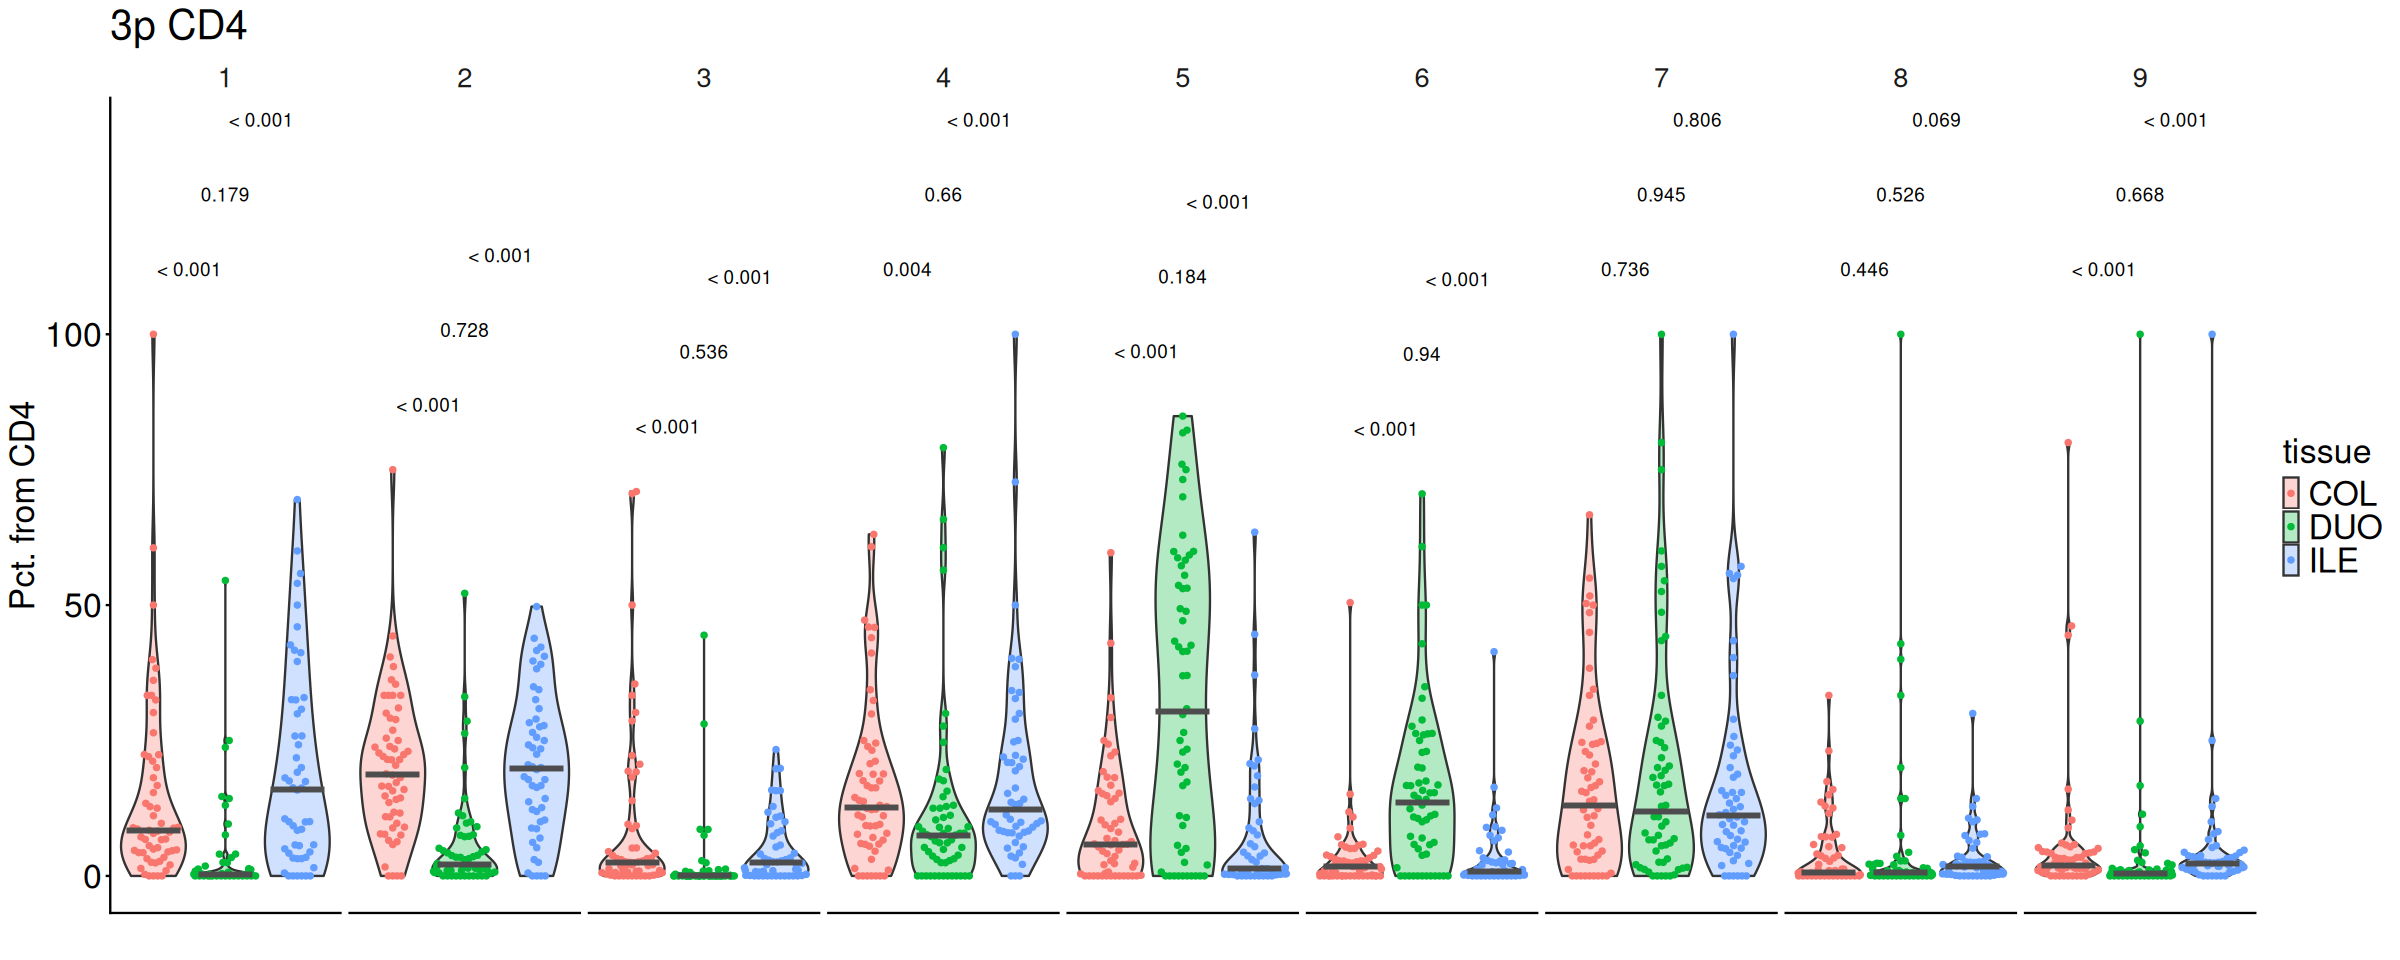

In [140]:
options(repr.plot.width = 20, repr.plot.height = 8)
df_filt <- df4 %>% 
left_join(pt_df)  %>% 
dplyr::filter(disease %in% c("UC","CD","FGID","HEA") )

stat_test <- df_filt %>%
mutate(freq100 = freq*100)  %>% 
  group_by(seurat_clusters) %>%
  rstatix::wilcox_test(freq100 ~ tissue) %>%
  mutate(p.label = ifelse(p < 0.001, "< 0.001", round(p, 3))) %>%
  rstatix::add_y_position() 

df_filt  %>% 
ggplot(aes(x = tissue, y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = tissue), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = tissue), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, ncol = 10) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "3p CD4") +
#ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(1,4)), label = "p.signif") +
stat_pvalue_manual(
    stat_test, label = "p.label", 
    #y.position = 60,
    remove.bracket = TRUE
    ) + 
ggtheme()
 


Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_segment()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_segment()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_segment()`).”


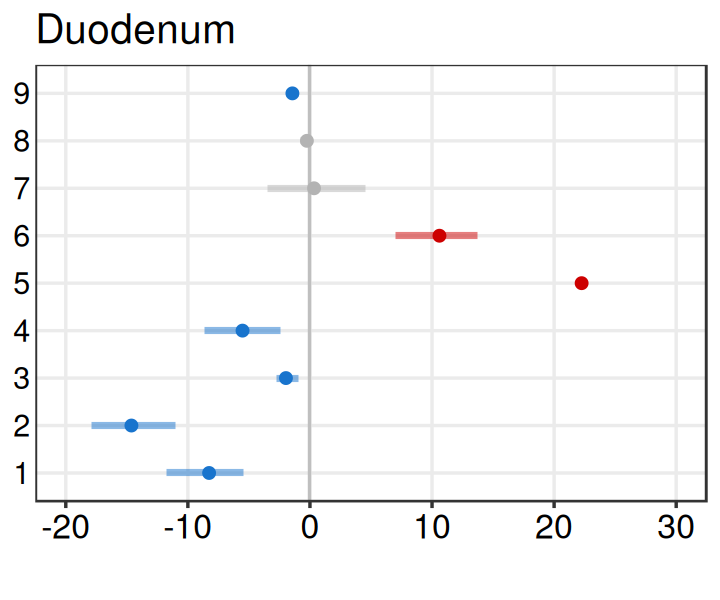

In [141]:
stat_test <- df_filt %>%
mutate(freq100 = freq*100)  %>%
mutate(duo = ifelse(tissue == "DUO","DUO","Other"))  %>% 
  group_by(seurat_clusters) %>%
  rstatix::wilcox_test(freq100 ~ duo, detailed = TRUE) 

options(repr.plot.width = 6, repr.plot.height = 5)
stat_test %>%
  mutate(upper = conf.high,
         lower = conf.low) %>%
  #mutate(across(all_of(c(
  #  "estimate", "lower", "upper"
  #)), exp)) %>%
  mutate(upper = ifelse(upper > 75, 74.9999, upper)) %>%
  mutate(lower = ifelse(lower < -25, -24.9999, lower)) %>%
  arrange(seurat_clusters) %>%
  ggplot(aes(estimate, seurat_clusters,
             color = ifelse(p*9>0.05,"1",ifelse(estimate > 1,"2","3")))) +
  geom_vline(xintercept = 0, color = "gray75") +
  geom_linerange(aes(xmin = lower, xmax = upper),
                 size = 1.5,
                 alpha = 0.5) +
  geom_point(size = 2.5) +
  theme_bw(base_size = 16) +
  scale_color_manual(values = c("3" = "dodgerblue3", "1" = "grey70","2" = "red3"), guide = "none") +
  xlim(c(-20, 30)) +
  labs(title = "Duodenum", y = NULL,
       x = "") +
  theme(axis.text.y = element_text(hjust = 0, size = 18),
        panel.grid.minor = element_blank(), 
        axis.ticks.y = element_blank(), 
                axis.text = element_text(color = "black")) + ggtheme()


ggsave("figures/freq_of_populations_in_tissues_3p/duodenum.png", width = 7, height = 11, units = "cm", create.dir = T)
ggsave("figures/freq_of_populations_in_tissues_3p/duodenum.svg", width = 7, height = 11, units = "cm", create.dir = T)

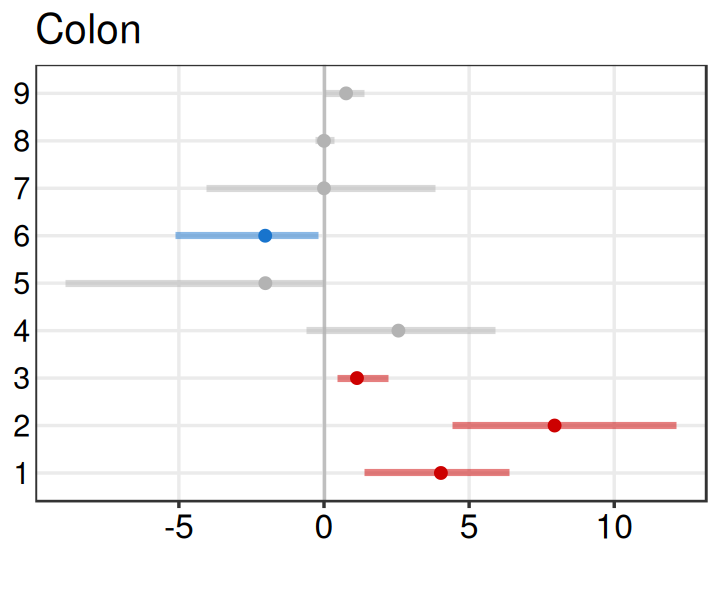

In [142]:
stat_test <- df_filt %>%
mutate(freq100 = freq*100)  %>%
mutate(col = ifelse(tissue == "COL","COL","Other"))  %>% 
  group_by(seurat_clusters) %>%
  rstatix::wilcox_test(freq100 ~ col, detailed = TRUE) 

stat_test %>%
  mutate(upper = conf.high,
         lower = conf.low) %>%
  #mutate(across(all_of(c(
  #  "estimate", "lower", "upper"
  #)), exp)) %>%
  mutate(upper = ifelse(upper > 75, 74.9999, upper)) %>%
  mutate(lower = ifelse(lower < -25, -24.9999, lower)) %>%
  arrange(seurat_clusters) %>%
  ggplot(aes(estimate, seurat_clusters,
             color = ifelse(p*9>0.05,"1",ifelse(estimate > 1,"2","3")))) +
  geom_vline(xintercept = 0, color = "gray75") +
  geom_linerange(aes(xmin = lower, xmax = upper),
                 size = 1.5,
                 alpha = 0.5) +
  geom_point(size = 2.5) +
  theme_bw(base_size = 16) +
  scale_color_manual(values = c("3" = "dodgerblue3", "1" = "grey70","2" = "red3"), guide = "none") +
  #xlim(c(-20, 30)) +
  labs(title = "Colon", y = NULL,
       x = "") +
  theme(axis.text.y = element_text(hjust = 0, size = 18),
        panel.grid.minor = element_blank(), 
        axis.ticks.y = element_blank(), 
                axis.text = element_text(color = "black")) + ggtheme()

ggsave("figures/freq_of_populations_in_tissues_3p/colon.png", width = 7, height = 11, units = "cm", create.dir = T)
ggsave("figures/freq_of_populations_in_tissues_3p/colon.svg", width = 7, height = 11, units = "cm", create.dir = T)

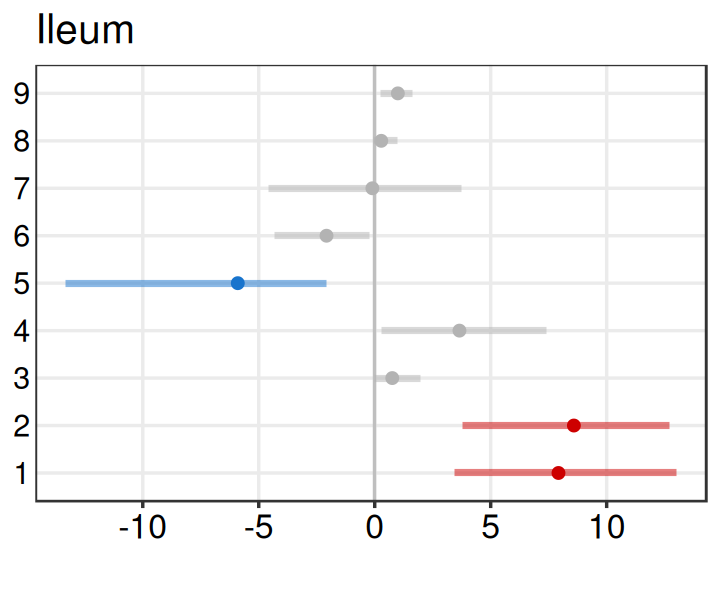

In [143]:
stat_test <- df_filt %>%
mutate(freq100 = freq*100)  %>%
mutate(ile = ifelse(tissue == "ILE","ILE","Other"))  %>% 
  group_by(seurat_clusters) %>%
  rstatix::wilcox_test(freq100 ~ ile, detailed = TRUE) 

stat_test %>%
  mutate(upper = conf.high,
         lower = conf.low) %>%
  #mutate(across(all_of(c(
  #  "estimate", "lower", "upper"
  #)), exp)) %>%
  mutate(upper = ifelse(upper > 75, 74.9999, upper)) %>%
  mutate(lower = ifelse(lower < -25, -24.9999, lower)) %>%
  arrange(seurat_clusters) %>%
  ggplot(aes(estimate, seurat_clusters,
             color = ifelse(p*9>0.05,"1",ifelse(estimate > 1,"2","3")))) +
  geom_vline(xintercept = 0, color = "gray75") +
  geom_linerange(aes(xmin = lower, xmax = upper),
                 size = 1.5,
                 alpha = 0.5) +
  geom_point(size = 2.5) +
  theme_bw(base_size = 16) +
  scale_color_manual(values = c("3" = "dodgerblue3", "1" = "grey70","2" = "red3"), guide = "none") +
  #xlim(c(-20, 30)) +
  labs(title = "Ileum", y = NULL,
       x = "") +
  theme(axis.text.y = element_text(hjust = 0, size = 18),
        panel.grid.minor = element_blank(), 
        axis.ticks.y = element_blank(), 
                axis.text = element_text(color = "black")) + ggtheme()

ggsave("figures/freq_of_populations_in_tissues_3p/ileum.png", width = 7, height = 11, units = "cm", create.dir = T)
ggsave("figures/freq_of_populations_in_tissues_3p/ileum.svg", width = 7, height = 11, units = "cm", create.dir = T)

In [144]:
df4

data_folder,seurat_clusters,freq,time,tissue,layer,patient
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>
HE-001-014 COL EPI T0,2,0.07692308,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,1,0.15384615,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,4,0.07692308,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,8,0.23076923,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,9,0.46153846,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,5,0.00000000,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,7,0.00000000,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,3,0.00000000,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,6,0.00000000,T0,COL,EPI,HE-001-014


In [145]:
options(repr.plot.width = 20, repr.plot.height = 4)

stat_test <- df_filt %>%
mutate(freq100 = freq*100)  %>% 
  group_by(seurat_clusters) %>%
  rstatix::wilcox_test(freq100 ~ layer) %>%
  mutate(p.label = ifelse(p < 0.001, "< 0.001", round(p, 3))) %>%
  rstatix::add_y_position() 

In [146]:
df_filt

data_folder,seurat_clusters,freq,time,tissue,layer,patient,disease,antiTNF_response
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
HE-001-014 COL EPI T0,2,0.07692308,T0,COL,EPI,HE-001-014,HEA,NM
HE-001-014 COL EPI T0,1,0.15384615,T0,COL,EPI,HE-001-014,HEA,NM
HE-001-014 COL EPI T0,4,0.07692308,T0,COL,EPI,HE-001-014,HEA,NM
HE-001-014 COL EPI T0,8,0.23076923,T0,COL,EPI,HE-001-014,HEA,NM
HE-001-014 COL EPI T0,9,0.46153846,T0,COL,EPI,HE-001-014,HEA,NM
HE-001-014 COL EPI T0,5,0.00000000,T0,COL,EPI,HE-001-014,HEA,NM
HE-001-014 COL EPI T0,7,0.00000000,T0,COL,EPI,HE-001-014,HEA,NM
HE-001-014 COL EPI T0,3,0.00000000,T0,COL,EPI,HE-001-014,HEA,NM
HE-001-014 COL EPI T0,6,0.00000000,T0,COL,EPI,HE-001-014,HEA,NM


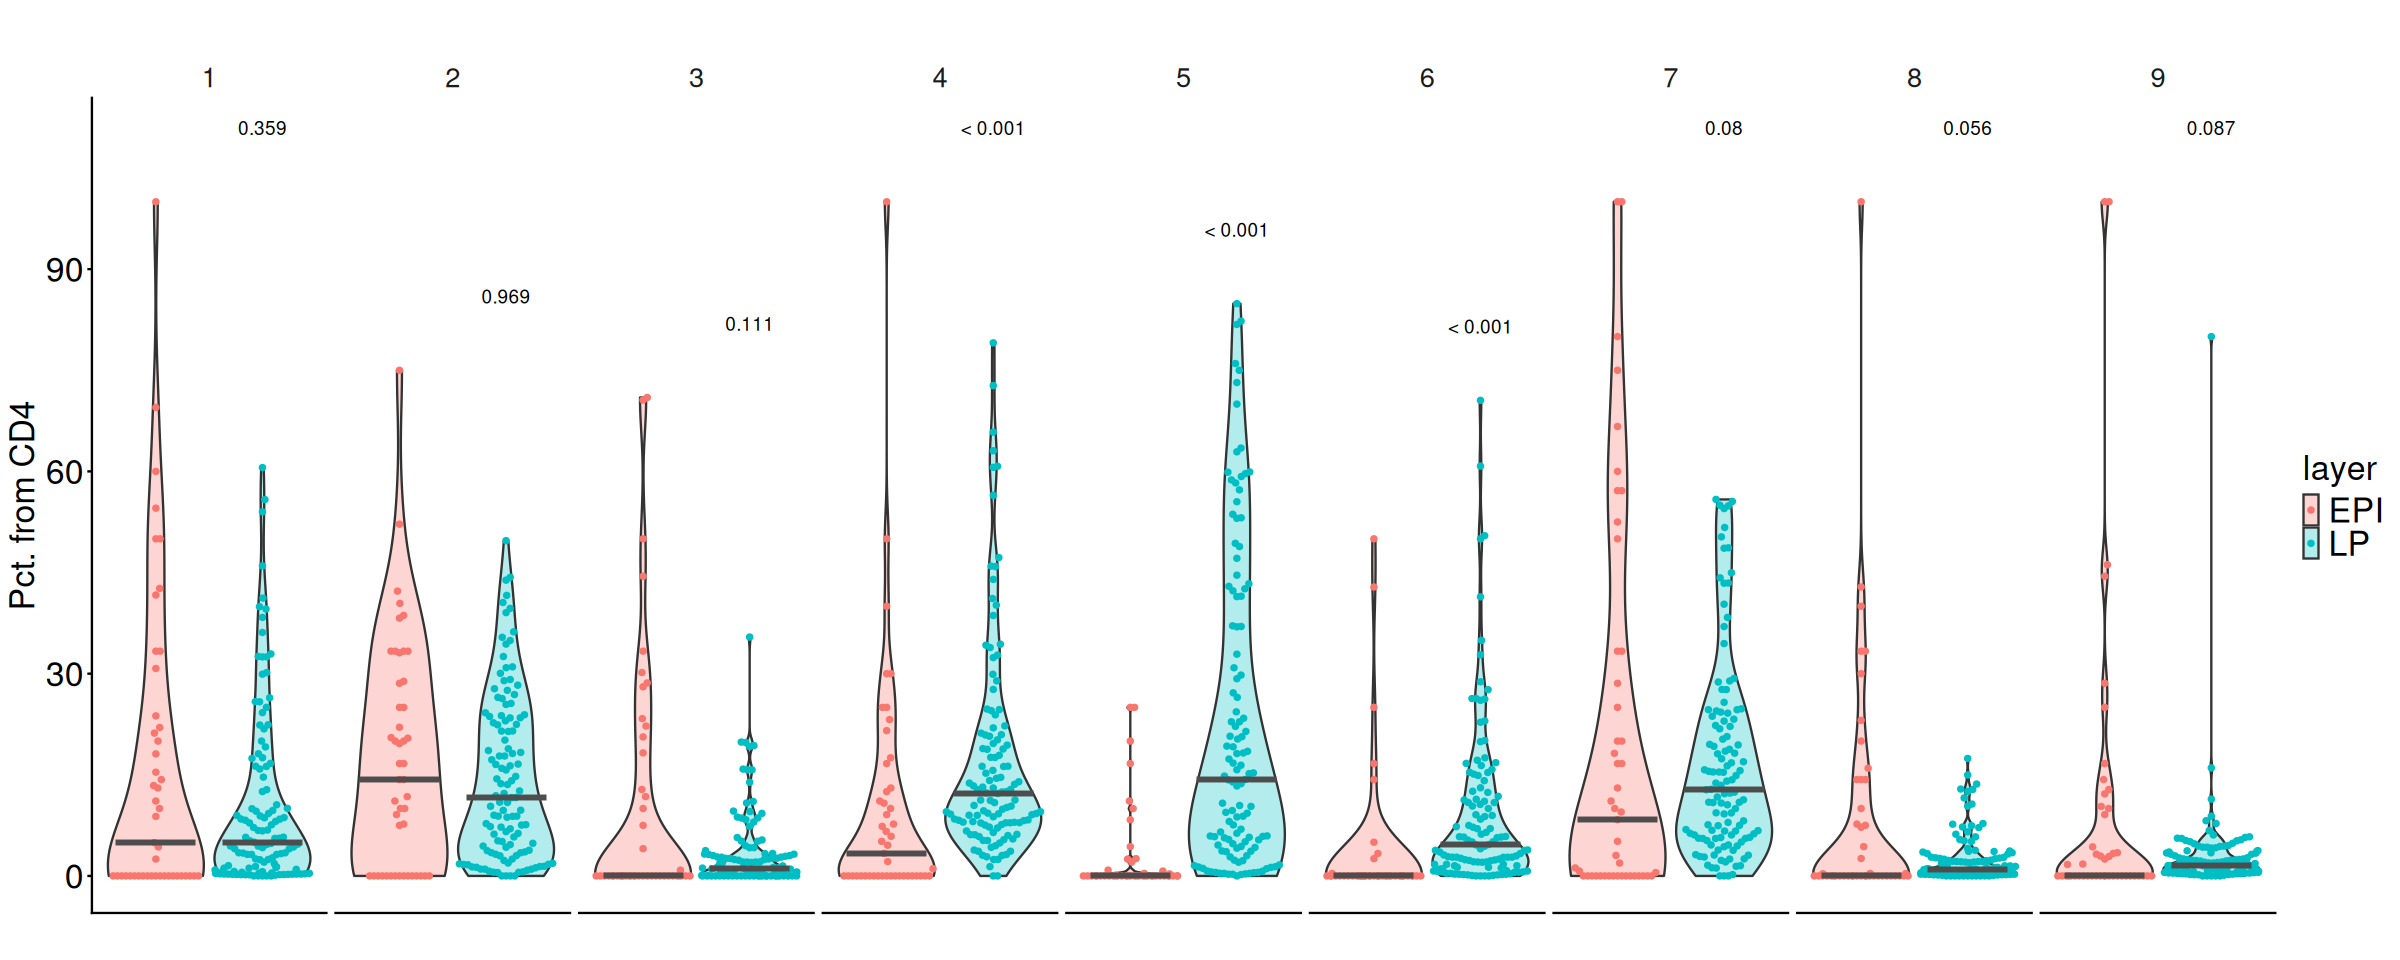

In [147]:
options(repr.plot.width = 20, repr.plot.height = 8)
df_filt  %>% 
ggplot(aes(x = layer, y = freq*100)) + # you can change the x to whatever variable you're interested in
geom_violin(alpha = 0.3, aes(fill = layer), scale = "width") + 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = layer), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, ncol = 10) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  #scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "") +
#ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(1,4)), label = "p.signif") +
stat_pvalue_manual(
    stat_test, label = "p.label", 
    #y.position = 60,
    remove.bracket = TRUE
    ) + 
ggtheme()
 
#ggsave("figures/boxplot_freq_gut_5p_24/241220_cdn_5p_layer.svg", width = 40, height = 9, units = "cm")
#ggsave("figures/boxplot_freq_gut_5p_24/241220_cdn_5p_layer.png", width = 40, height = 9, units = "cm")

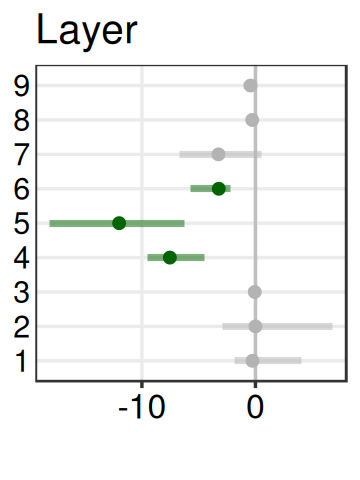

In [148]:
stat_test <- df_filt %>%
mutate(freq100 = freq*100)  %>% 
  group_by(seurat_clusters) %>%
  rstatix::wilcox_test(freq100 ~ layer, detailed = TRUE) 

options(repr.plot.width = 3, repr.plot.height = 4)

stat_test %>%
  mutate(upper = conf.high,
         lower = conf.low) %>%
  #mutate(across(all_of(c(
  #  "estimate", "lower", "upper"
  #)), exp)) %>%
  mutate(upper = ifelse(upper > 75, 74.9999, upper)) %>%
  mutate(lower = ifelse(lower < -25, -24.9999, lower)) %>%
  arrange(seurat_clusters) %>%
  ggplot(aes(estimate, seurat_clusters, 
             color = ifelse(p*9>0.05,"1",ifelse(estimate > 1,"2","3")))) +
  geom_vline(xintercept = 0, color = "gray75") +
  geom_linerange(aes(xmin = lower, xmax = upper),
                 size = 1.5,
                 alpha = 0.5) +
  geom_point(size = 2.5) +
  theme_bw(base_size = 16) +
  scale_color_manual(values = c("3" = "darkgreen", "1" = "grey70","2" = "orange3"), guide = "none") +
  #xlim(c(-20, 30)) +
  labs(title = "Layer", y = NULL,
       x = "") +
    theme(axis.text.y = element_text(hjust = 0, size = 18),
        panel.grid.minor = element_blank(), 
        axis.ticks.y = element_blank(), 
                axis.text = element_text(color = "black")) + ggtheme()

ggsave("figures/freq_of_populations_in_tissues_3p/layer.png", width = 9.5, height = 11, units = "cm", create.dir = T)
ggsave("figures/freq_of_populations_in_tissues_3p/layer.svg", width = 9.5, height = 11, units = "cm", create.dir = T)

# Marker heatmap

In [191]:
markers2 <- c(
  "LEF1", "CCR7", "SELL", "TCF7", "IL21",
  "CXCL13", "CXCR5", "IL4", "TNFRSF18", "IL2RA",
  "CTLA4", "IKZF2", "FOXP3", "KLRB1", "GATA3",
  "CCL5", "CD40LG", "GPR183", "GNLY", "GZMB",
  "IL17F", "HLA-DRA", "IFNG", "IL26", "PRF1",
  "IL22", "CXCR3", "CXCR6", "IL5", "IL23R",
  "RORC", "RORA", "CCR6", "TNF", "IL17A",
  "TBX21", "IL13", "S100A6", "KLRD1", "CD160",
  "XCL1"
)

In [193]:

avgexp = AverageExpression(cd4_3p_int, features = markers2, group.by = "seurat_clusters",
                          assay = "RNA")

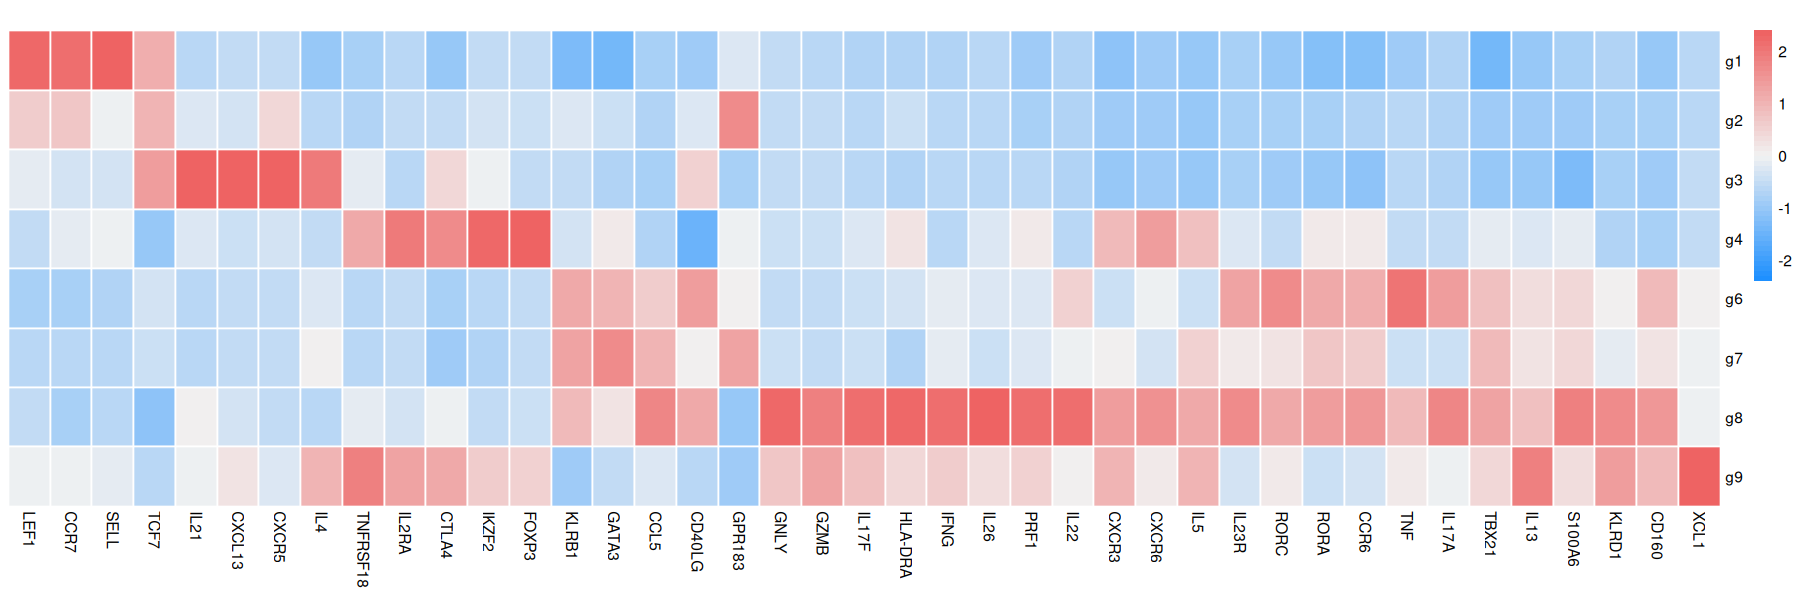

In [197]:
options(repr.plot.width = 15, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp$RNA)[c(3,1,7,5,6,4,8,9),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9)

In [112]:
dir.create("figures/characterization_CD4CTL/")

In [198]:
pheatmap::pheatmap(t(avgexp$RNA)[c(3,1,7,5,6,4,8,9),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9, filename = "figures/characterization_CD4CTL/heatmap_cluster_markers_3p.pdf",
                  width = 12, height = 4)

# CollecTRI 3p dataset

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



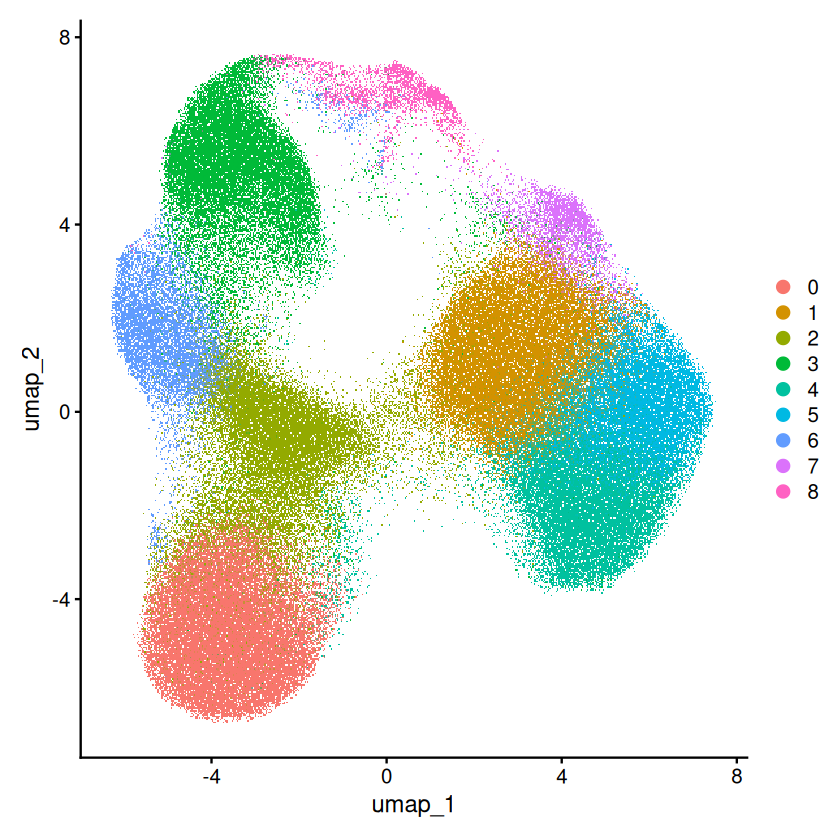

In [5]:
DimPlot(cd4)

net <- decoupleR::get_progeny(organism = 'human', top = 200)
net2 <- decoupleR::get_collectri(organism='human', split_complexes=FALSE)

options(future.globals.maxSize = 30000 * 1024^2)

 data <- cd4

In [6]:
# Extract the normalized log-transformed counts
mat <- as.matrix(data@assays$RNA$data)

Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 34.1 GiB”


In [7]:
# Extract the normalized log-transformed counts
mat <- as.matrix(data@assays$RNA$data)

######## Pathways Progeny #########   
    
# Run wmean
acts <- decoupleR::run_wmean(mat=mat, net=net, .source='source', .target='target',
                  .mor='weight', times = 100, minsize = 5)
  
# Add data to Seurat object

  data[['pathwayswmean']] <- acts %>%
  filter(statistic == 'norm_wmean') %>%
  pivot_wider(id_cols = 'source', names_from = 'condition',
              values_from = 'score') %>%
  column_to_rownames('source') %>%
  Seurat::CreateAssayObject(.)

  # Scale the data
DefaultAssay(object = data) <- "pathwayswmean"

Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 34.1 GiB”


In [8]:
######## CollecTRI ######### 

# Run ULM
acts <- decoupleR::run_ulm(mat=mat, net=net2, .source='source', .target='target',
                .mor='mor', minsize = 5)
  
# Add data to Seurat object
  data[['CollecTRI']] <- acts %>%
  pivot_wider(id_cols = 'source', names_from = 'condition',
              values_from = 'score') %>%
  column_to_rownames('source') %>%
  Seurat::CreateAssayObject(.)

  # Scale the data
DefaultAssay(object = data) <- "CollecTRI"

In [9]:
DefaultAssay(data)  <- "CollecTRI"

In [10]:
Idents(data)  <- data$seurat_clusters

In [11]:
coll  <- FindAllMarkers(data, only.pos = T)

Calculating cluster 0

Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Warning message in mean.fxn(object[features, cells.2, drop = FALSE]):
“NaNs produced”
Warning message:
“`PackageCheck()` was deprecated in SeuratObject 5.0.0.
ℹ Please use `rlang::check_installed()` instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Calculating cluster 1

Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Warning message in mean.fxn(object[features, cells.2, drop = FALSE]):
“NaNs produced”
Calculating cluster 2

Warning message in mean.fxn(object[features,

In [13]:
data

An object of class Seurat 
29267 features across 166659 samples within 4 assays 
Active assay: CollecTRI (759 features, 0 variable features)
 2 layers present: counts, data
 3 other assays present: RNA, integrated, pathwayswmean
 2 dimensional reductions calculated: pca, umap

In [14]:
coll

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
ZBTB14,0,1.6850966,0.837,0.502,0,0,ZBTB14
TRERF1,0,1.2850291,0.619,0.325,0,0,TRERF1
MZF1,0,5.1950389,0.453,0.177,0,0,MZF1
KLF2,0,3.0502178,0.486,0.290,0,0,KLF2
DNMT3B,0,0.7273330,0.645,0.480,0,0,DNMT3B
BCL6,0,0.7733485,0.689,0.541,0,0,BCL6
NR2C2,0,0.3861741,0.725,0.603,0,0,NR2C2
POU5F1,0,0.3887916,0.897,0.790,0,0,POU5F1
POU3F1,0,0.2280084,0.831,0.740,0,0,POU3F1


In [12]:
saveRDS(data, "..//241201_VN_PREDICT2/gut_3p_integrated_filt_without_ilc_v4_just_cd4_collectri.rds")

In [18]:
markers2  <- unique(c('TBX21', 'EOMES', 'TCF7', 'LEF1', 'BCL6', 'PRDM1', 'IRF4', 'BATF', 'BATF3', 'TOX', 'TOX2', 'ZEB2', 'ZEB1', 'ID2', 'ID3', 'BACH2', 'ZBTB7B', 'RUNX3', 'RUNX1', 'BCL11B', 'TCF3', 'TCF12', 'GATA3', 'RORC', 'RORA', 'FOXP3', 'IKZF2', 'IKZF1', 'IKZF3', 'STAT1', 'STAT3', 'STAT4', 'STAT5A', 'STAT5B', 'STAT6', 'NFATC1', 'NFATC2', 'RELA', 'NFKB1', 'NFKB2', 'REL', 'BCL10', 'FOXO1', 'FOXO3', 'FOXP1', 'NR4A1', 'NR4A2', 'NR4A3', 'ZBTB16', 'AHR', 'HIF1A', 'BHLHE40', 'EGR2', 'EGR3', 'EGR1', 'ETS1', 'ELF4', 'KLF2', 'KLF3', 'KLF13', 'KLF6', 'MYB', 'BCL3', 'ZFP683', 'PRDM1', 'RBPJ', 'NOTCH1', 'ZBTB20', 'TCF7', 'MAF', 'BCL6B', 'ZFP683', 'ZBTB32', 'TOX2', 'POU2F2', 'NR3C1', 'BHLHE41', 'NR2F6', 'HIC1', 'BCL6', 'TFAP4', 'SNAI3', 'BATF', 'MAZR', 'ZBTB7A', 'SOX13', 'SOX4', 'NFIL3', 'IRF4', 'JUN', 'JUNB', 'FOS', 'FOSL2', 'E2F1', 'SMAD3', 'SMAD2', 'RFX5', 'HHEX', 'ARNTL', 'NRF1', 'PPARG', 'NR1D1',"IKZF1","IKZF3","IKZF4"))

In [19]:
avgexp = AverageExpression(data, features = markers2, group.by = "seurat_clusters",
                          assay = "RNA")

As of Seurat v5, we recommend using AggregateExpression to perform pseudo-bulk analysis.
This message is displayed once per session.
First group.by variable `seurat_clusters` starts with a number, appending `g` to ensure valid variable names
This message is displayed once every 8 hours.
Warning message:
“The following 2 features were not found in the RNA assay: ZFP683, MAZR”


In [20]:
dir.create("figures/heatmaps_tf/")

In [21]:
options(repr.plot.width = 17, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 13, filename = "figures/heatmaps_tf/expression_tf_3.pdf", width = 17, height = 4)

In [22]:
data

An object of class Seurat 
29267 features across 166659 samples within 4 assays 
Active assay: CollecTRI (759 features, 0 variable features)
 2 layers present: counts, data
 3 other assays present: RNA, integrated, pathwayswmean
 2 dimensional reductions calculated: pca, umap

In [23]:
avgexp = AverageExpression(data, features = markers2, group.by = "seurat_clusters",
                          assay = "CollecTRI")

options(repr.plot.width = 17, repr.plot.height = 5)
    pheatmap::pheatmap(t(avgexp$CollecTRI), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 13, filename = "figures/heatmaps_tf/collectri_tf_3.pdf", width = 17, height = 4)

Warning message:
“The following 10 features were not found in the CollecTRI assay: BATF3, TOX2, BCL10, ZFP683, ZBTB20, BCL6B, SNAI3, MAZR, SOX13, ARNTL”


Warning message:
“The following 10 features were not found in the CollecTRI assay: BATF3, TOX2, BCL10, ZFP683, ZBTB20, BCL6B, SNAI3, MAZR, SOX13, ARNTL”


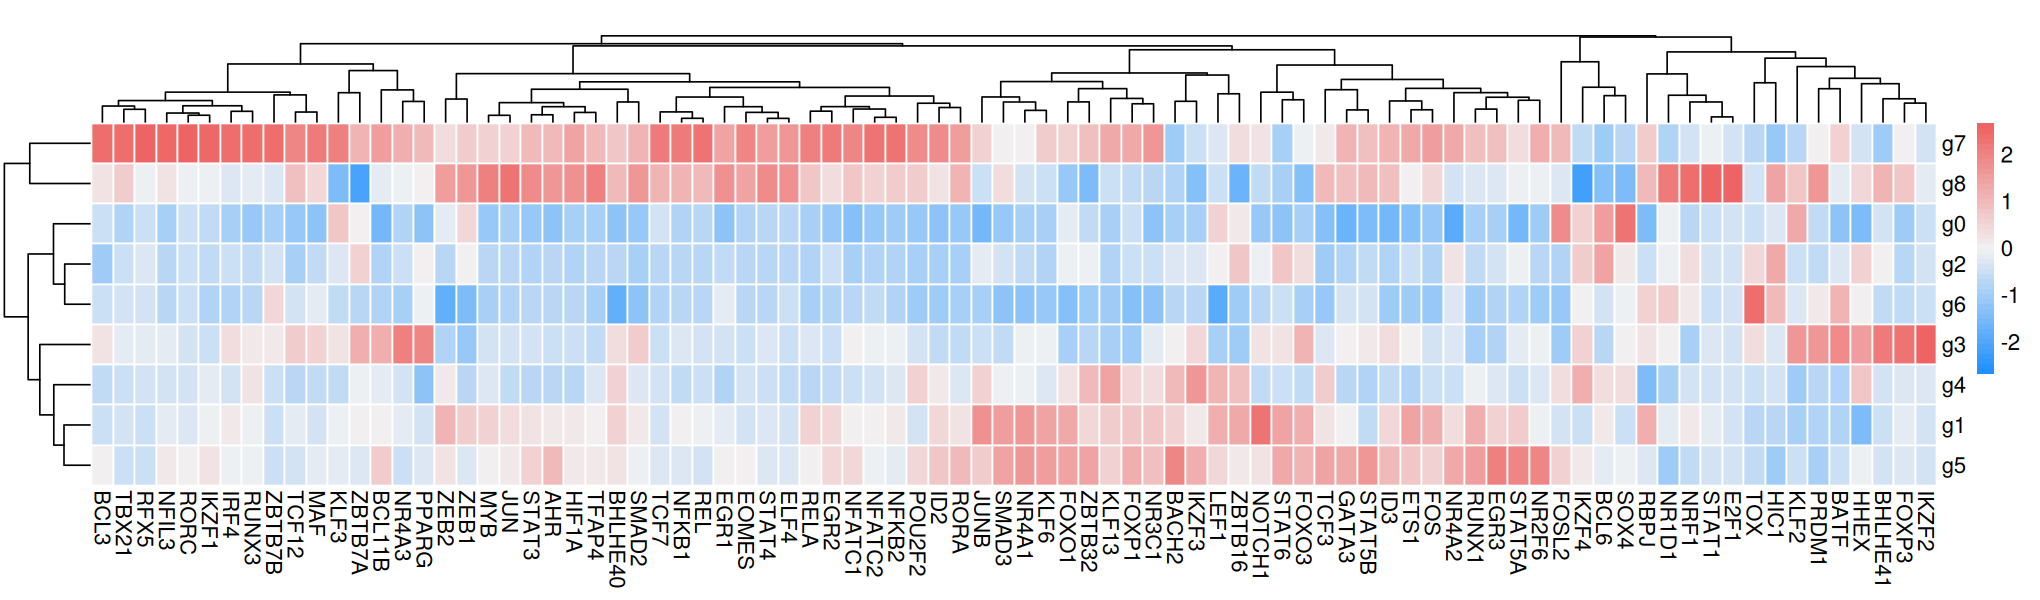

In [24]:
avgexp = AverageExpression(data, features = markers2, group.by = "seurat_clusters",
                          assay = "CollecTRI")

options(repr.plot.width = 17, repr.plot.height = 5)
    pheatmap::pheatmap(t(avgexp$CollecTRI), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 13, width = 17, height = 4)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



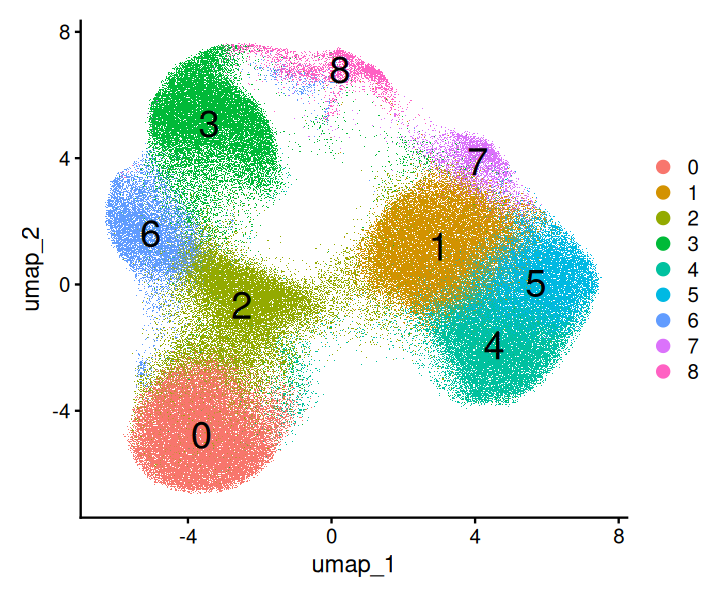

In [26]:
options(repr.plot.width = 6, repr.plot.height = 5)
DimPlot(cd4, label = T, label.size = 8)

In [30]:
markers3  <- c("BCL3","TBX21","STAT5A","IRF4","NFATC1","NFATC2","STAT1","STAT3","BATF","REL","RELA","NFIL3","RUNX3","ELF4","RORC","IKZF1","EOMES","RBPJ","BHLHE40")

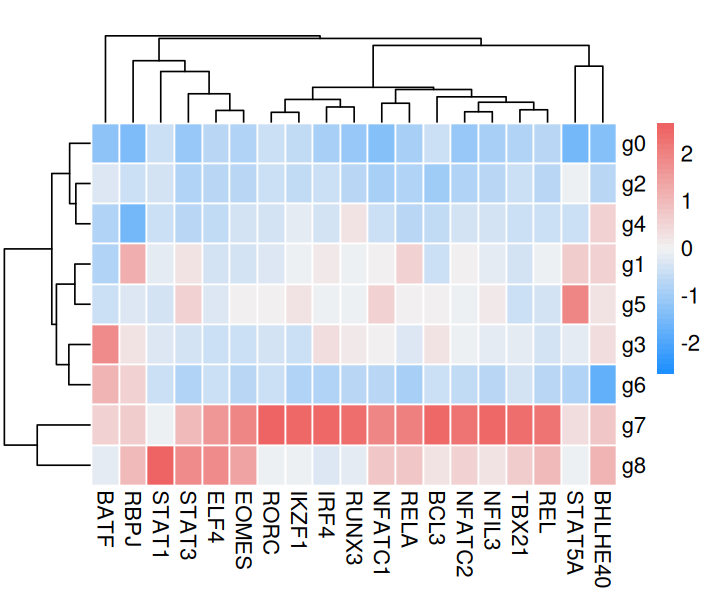

In [31]:
avgexp = AverageExpression(data, features = markers3, group.by = "seurat_clusters",
                          assay = "CollecTRI")

options(repr.plot.width = 6, repr.plot.height = 5)
    pheatmap::pheatmap(t(avgexp$CollecTRI), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 13, width = 17, height = 4)